# 04 – Models in cross-validation (tasks 18, 20, 21, 22, 23)

All model variants of the project are trained **once** here, on the same folds and with the same measures,
and then compared in one table.

**How we compare models**
- Data: `load_cv()` from `03_split_pipeline.ipynb` (task 16). The test set is not in it.
- In every fold, the model is trained on **all buildings** of the other four folds and judged on the **houses** of the
  validation fold (feedback point 1). Results for all buildings are shown next to them.
- Selection measure (README decision 1): share of houses above 450 among the top 20% of the ranking.
- All models use the preprocessing pipeline in `pipeline.py` (task 19) and the cross-validation in `cv.py`.
- Ridge, lasso and logistic regression: for each variant we choose the setting (alpha or C) with the highest mean
  selection measure over the 5 folds; if several have the same mean, the one with the smaller MAE on houses wins
  (README decision 14).

**Structure**
1. Load the data
2. The list of all variants. **To add a variant (e.g. a tree model), add one line there.**
3. Train all variants (one loop)
4. Task 18: baselines
5. Task 20: linear regression, ridge and lasso
6. Task 21: classification variant
7. Task 22: feature sets
8. Task 23: trained on houses only vs. all buildings
9. All variants against their reference, and save

**What the pipeline does** (fitted on the training part only):

| Branch | Columns | Steps |
|---|---|---|
| numeric | floor_area, floors, dwellings | fill missing with the training median → log → scale |
| categorical | construction_period, building_class, energy_group, heating_system | one 0/1 column per category; rare ones (< 20) merged into "infrequent" |
| municipality | municipality | one 0/1 column per municipality |
| expert rule | construction_period × energy_group | average target of the combination, pulled towards the overall mean (target encoding) → scale |

Runs about 4 minutes (most of it the search for alpha).

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)

from config import THRESHOLD, TABLES, FIGURES, load_cv
from metrics import evaluate
from pipeline import split_xy, build_pipeline, build_preprocessor, AboveThreshold, ExpertRuleBaseline
from cv import (cross_validate, summarize, tune_alpha, best_alpha, plot_validation_curve, plot_lasso_path,
                show, paired_difference)

## 1. Load the data

Only the buildings for cross-validation; the test set stays in `test.csv` until task 26.

In [3]:
train = load_cv()
X, y, is_house, groups = split_xy(train)
folds = train["fold"].to_numpy()

print("Buildings in cross-validation:", len(train), "| of which houses:", is_house.sum())

per_fold = train.groupby("fold").agg(buildings=("EGID", "size"), houses=("house", "sum"))
per_fold["houses above 450 (%)"] = train[train["house"]].groupby("fold")["y"].apply(lambda s: (s > THRESHOLD).mean() * 100).round(1)
per_fold["houses in top 20%"] = (per_fold["houses"] * 0.2).round().astype(int)
per_fold

Buildings in cross-validation: 12710 | of which houses: 1171


,buildings,houses,houses above 450 (%),houses in top 20%
fold,,,,
0,2542,234,36.3,47
1,2545,235,39.6,47
2,2541,234,37.6,47
3,2541,234,38.9,47
4,2541,234,37.6,47


**Reading the numbers.** If the office picked houses at random, about the share of houses above 450 shown above
(~38%) would be problem houses. A useful model must be clearly above that. With about 47 houses in the top 20%
of a fold, one house more or less changes the measure by about 2 percentage points, so small differences
between models are chance.

## 2. The variants

**Models.** Each model has a name, the model itself, the setting we tune (or none) and whether it predicts the index.
Logistic regression predicts the probability of being above 450; `AboveThreshold` (in `pipeline.py`) turns the index
into "above 450 or not" inside the model, so the preprocessing still learns from the index, as for the regressions.
The baselines need no preprocessing.

**Variants.** One line per variant: task, model, label, feature switches (`build_pipeline`) and the training rows.
The **reference** of each model uses all features (with the expert rule) and learns from all buildings;
every other variant changes one thing.

In [4]:
RIDGE_ALPHAS = np.logspace(-2, 5, 29)   # 0.01 to 100,000
LASSO_ALPHAS = np.logspace(-3, 2, 26)   # 0.001 to 100 (above that lasso sets almost all coefficients to zero)
C_VALUES = [0.001, 0.01, 0.1, 1, 10, 100]

def logistic(C):
    return AboveThreshold(LogisticRegression(C=C, max_iter=5000))

# name -> (model class or function, tuning (setting, values) or None, extra arguments, predicts the index?)
MODELS = {
    "Linear regression":   (LinearRegression, None, {}, True),
    "Ridge":               (Ridge, ("alpha", RIDGE_ALPHAS), {}, True),
    "Lasso":               (Lasso, ("alpha", LASSO_ALPHAS), {"max_iter": 10000}, True),
    "Logistic regression": (logistic, ("C", C_VALUES), {}, False),
}
BASELINES = {   # no preprocessing, no tuning
    "Training mean": DummyRegressor,        # every building gets the mean index of the training folds
    "Expert rule":   ExpertRuleBaseline,    # mean index of construction period x energy group (decision 12)
}

def variant(task, model, label, train_on="all", **switches):
    return {"task": task, "model": model, "label": label, "train_on": train_on, "switches": switches}

VARIANTS = [
    variant(18, "Training mean", "baseline"),
    variant(18, "Expert rule", "baseline"),
    # task 20: with and without the expert-rule column
    variant(20, "Linear regression", "reference"),
    variant(20, "Linear regression", "no expert rule", expert_rule=False),
    variant(20, "Ridge", "reference"),
    variant(20, "Ridge", "no expert rule", expert_rule=False),
    variant(20, "Lasso", "reference"),
    variant(20, "Lasso", "no expert rule", expert_rule=False),
    # task 21: classification
    variant(21, "Logistic regression", "reference"),
    variant(21, "Logistic regression", "no expert rule", expert_rule=False),
    # task 22: feature sets (without heating, the expert rule drops out too, because it needs the energy group)
    *[variant(22, m, label, **switches)
      for m in ["Linear regression", "Ridge", "Lasso"]
      for label, switches in [("no municipality", {"municipality": False}),
                              ("no heating", {"heating": False, "expert_rule": False}),
                              ("no heating, no municipality", {"heating": False, "municipality": False, "expert_rule": False})]],
    # task 23: learn from the houses of the training folds only
    variant(23, "Linear regression", "houses only", train_on="houses"),
    variant(23, "Ridge", "houses only", train_on="houses"),
    # add new variants here, e.g. variant(24, "Tree", "reference") after adding "Tree" to MODELS
]
for v in VARIANTS:
    v["name"] = f"{v['model']}, {v['label']}"
assert len({v["name"] for v in VARIANTS}) == len(VARIANTS), "two variants have the same name"

pd.DataFrame([{"task": v["task"], "variant": v["name"], "trained on": v["train_on"],
               "switches": v["switches"] or "-"} for v in VARIANTS])

,task,variant,trained on,switches
0,18,"Training mean, baseline",all,-
1,18,"Expert rule, baseline",all,-
2,20,"Linear regression, reference",all,-
3,20,"Linear regression, no expert rule",all,{'expert_rule': False}
4,20,"Ridge, reference",all,-
5,20,"Ridge, no expert rule",all,{'expert_rule': False}
6,20,"Lasso, reference",all,-
7,20,"Lasso, no expert rule",all,{'expert_rule': False}
8,21,"Logistic regression, reference",all,-
9,21,"Logistic regression, no expert rule",all,{'expert_rule': False}


## 3. Train all variants

For every variant: if it has a setting, try all values in cross-validation and keep the best one; then run the
cross-validation once more with that value and keep the results per fold and the out-of-fold predictions
(every building predicted by the model that did not see it).

For "houses only", the model learns from the houses of the training folds only, but is judged on the same
validation houses as all other variants. Its numbers for "all buildings" are left empty: this model is not meant
for apartment blocks.

In [5]:
warnings.filterwarnings("ignore", message="Objective did not converge")  # lasso at the smallest alphas; results are stable

results = {}
for v in VARIANTS:
    train_rows = is_house if v["train_on"] == "houses" else None
    param, value, tuning = None, np.nan, None

    if v["model"] in BASELINES:
        make_model, predicts_index = BASELINES[v["model"]], True
    else:
        model, tune, kwargs, predicts_index = MODELS[v["model"]]
        if tune is None:
            make_model = lambda: build_pipeline(model(**kwargs), **v["switches"])
        else:
            param, values = tune
            tuning = tune_alpha(model, values, X, y, is_house, folds, model_kwargs=kwargs, param=param,
                                predicts_index=predicts_index, train_rows=train_rows, **v["switches"])
            value = best_alpha(tuning, param=param)
            make_model = lambda: build_pipeline(model(**{param: value}, **kwargs), **v["switches"])

    per_fold_v, oof = cross_validate(make_model, X, y, is_house, folds,
                                     predicts_index=predicts_index, train_rows=train_rows)
    summary = summarize(per_fold_v)
    if train_rows is not None:   # trained on houses only: no numbers for all buildings
        measures = [c for c in summary.columns if c != "group"]
        summary.loc[summary["group"] == "all buildings", measures] = np.nan
    results[v["name"]] = {**v, "param": param, "value": value, "tuning": tuning,
                          "per_fold": per_fold_v, "summary": summary, "oof": oof}
    print(f"{v['name']:<50}", "" if param is None else f"best {param} = {value:.3g}")

Training mean, baseline                            
Expert rule, baseline                              
Linear regression, reference                       
Linear regression, no expert rule                  
Ridge, reference                                   best alpha = 562
Ridge, no expert rule                              best alpha = 0.01
Lasso, reference                                   best alpha = 0.001
Lasso, no expert rule                              best alpha = 0.631
Logistic regression, reference                     best C = 10
Logistic regression, no expert rule                best C = 10
Linear regression, no municipality                 
Linear regression, no heating                      
Linear regression, no heating, no municipality     
Ridge, no municipality                             best alpha = 0.01
Ridge, no heating                                  best alpha = 31.6
Ridge, no heating, no municipality                 best alpha = 100
Lasso, no municipality     

In [6]:
def overview(names):
    # one row per variant: houses in full, the main numbers for all buildings next to them
    rows = []
    for name in names:
        r = results[name]
        houses, everyone = show(r["summary"], "houses"), show(r["summary"], "all buildings")
        rows.append({
            "variant": name,
            "setting": "–" if r["param"] is None else f"{r['param']} = {r['value']:.3g}",
            **houses,
            "all buildings: top 20%: above 450 (%)": everyone["top 20%: above 450 (%)"],
            "all buildings: MAE": everyone["MAE"],
        })
    return pd.DataFrame(rows).set_index("variant")

def names(task=None, model=None):
    return [v["name"] for v in VARIANTS if (task is None or v["task"] == task) and (model is None or v["model"] == model)]

random_share = (y[is_house] > THRESHOLD).mean()
print(f"Random choice: {random_share * 100:.1f}% of houses are above 450")

Random choice: 38.0% of houses are above 450


## 4. Task 18: baselines

Two simple approaches that every model must beat, scored on the same 5 folds and with the same measures as the models:
- **Training mean:** every building gets the average index of the training folds. All scores are equal, so the ranking is random; this is a sanity check (houses: about 38% above 450 in the top 20%, about 20% captured).
- **Expert rule:** every building gets the average index of its construction period × energy group in the training folds (feedback point 4: can the models beat it?). A combination not seen in training gets the overall mean.

In [7]:
overview(names(task=18))

,setting,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE,all buildings: top 20%: above 450 (%),all buildings: MAE
variant,,,,,,,,
"Training mean, baseline",–,34.0,3.9,34.5,18.0,117.5,28.8,94.8
"Expert rule, baseline",–,45.1,3.5,43.9,23.8,106.1,47.1,80.4


## 5. Task 20: linear regression, ridge and lasso

Each model is run **with and without** the expert-rule column (construction period × energy group, target encoding).

### 5a. Overview: all six variants with their chosen setting

Houses first, all buildings next to them.

In [8]:
overview(names(task=20))

,setting,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE,all buildings: top 20%: above 450 (%),all buildings: MAE
variant,,,,,,,,
"Linear regression, reference",–,54.0,3.1,49.2,28.6,104.8,57.0,75.4
"Linear regression, no expert rule",–,53.6,2.4,48.3,28.3,104.5,56.4,75.5
"Ridge, reference",alpha = 562,54.5,3.6,43.1,28.7,106.7,56.1,76.5
"Ridge, no expert rule",alpha = 0.01,53.6,2.4,48.3,28.3,104.5,56.4,75.5
"Lasso, reference",alpha = 0.001,54.0,3.1,49.2,28.6,104.9,57.1,75.4
"Lasso, no expert rule",alpha = 0.631,54.0,3.7,44.0,28.5,106.8,55.1,76.9


In [9]:
# linear regression per fold, houses only: how much does the measure move between folds?
pd.DataFrame({
    name: results[name]["per_fold"].query("group == 'houses'").set_index("fold")["share_above_top20"].mul(100).round(1)
    for name in names(task=20, model="Linear regression")
})

,"Linear regression, reference","Linear regression, no expert rule"
fold,,
0,46.8,48.9
1,46.8,46.8
2,61.7,57.4
3,57.4,57.4
4,57.4,57.4


### 5b. Which alpha? Validation curves

alpha sets how strongly large coefficients are penalised. We try values on a log scale: ridge from 0.01 to 100,000,
lasso from 0.001 to 100 (above that lasso sets almost all coefficients to zero).

Top: share of houses above 450 in the top 20% (mean over the 5 folds; band = ± one standard error).
Bottom: MAE on houses. The lines are references: random choice, the two baselines of task 18
and linear regression without penalty.

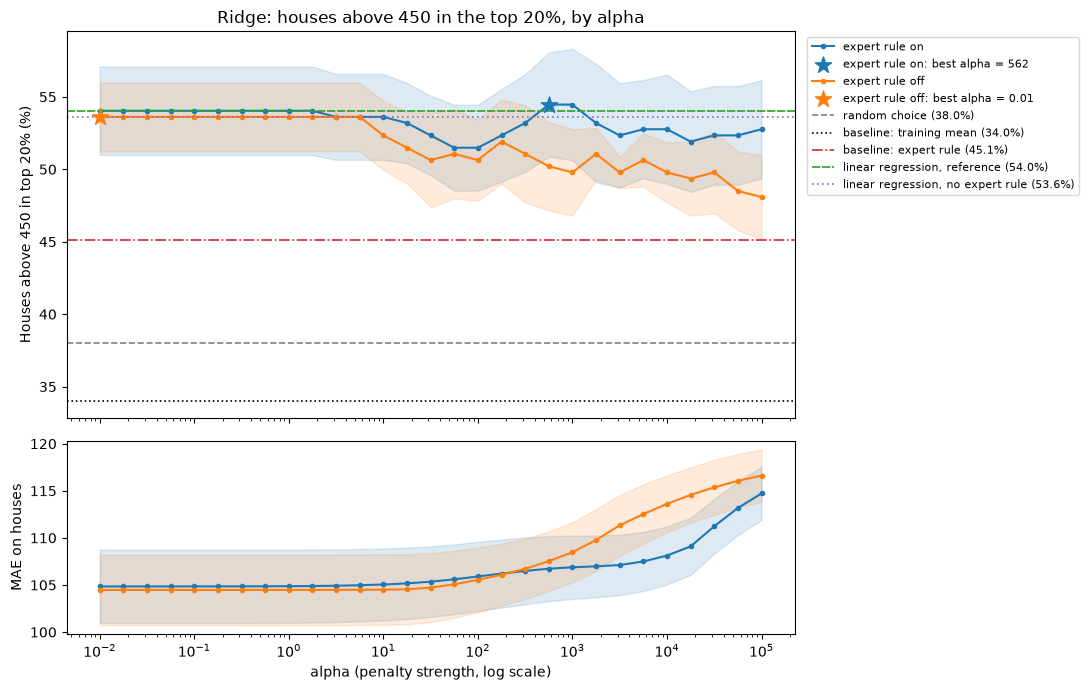

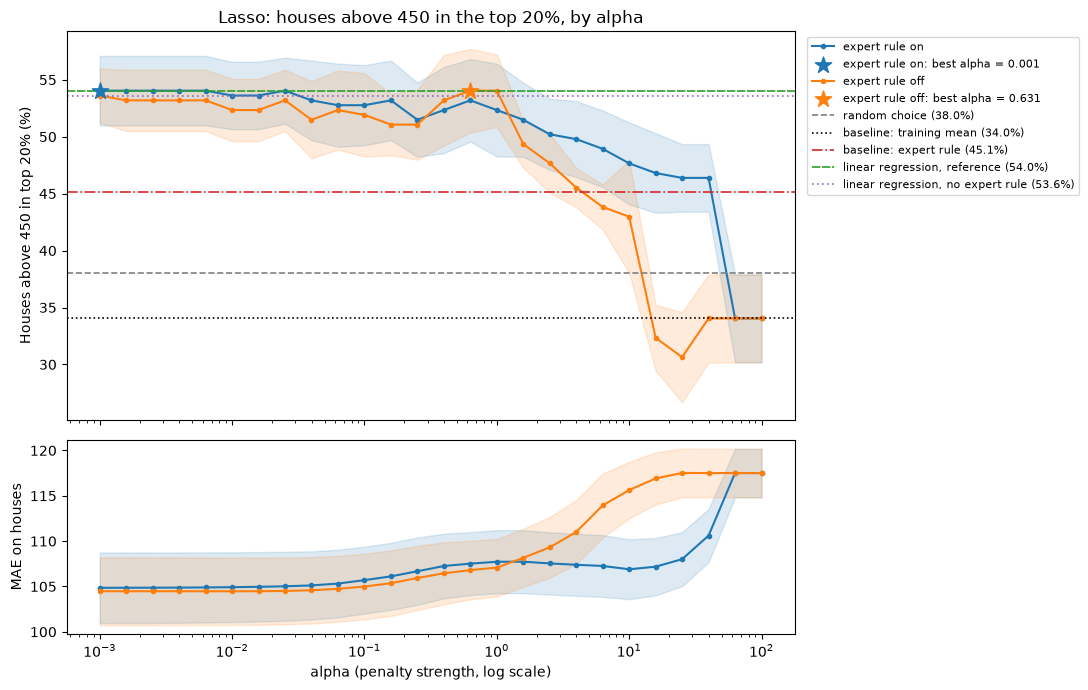

In [10]:
reference = {f"random choice ({random_share * 100:.1f}%)": random_share}
for name in names(task=18) + names(task=20, model="Linear regression"):
    share = results[name]["summary"].query("group == 'houses'")["share_above_top20_mean"].iloc[0]
    label = f"baseline: {name.split(',')[0].lower()}" if results[name]["task"] == 18 else name.lower()
    reference[f"{label} ({share * 100:.1f}%)"] = share

for model in ["Ridge", "Lasso"]:
    plot_validation_curve(
        {"expert rule on": results[f"{model}, reference"]["tuning"],
         "expert rule off": results[f"{model}, no expert rule"]["tuning"]},
        title=f"{model}: houses above 450 in the top 20%, by alpha",
        reference=reference,
        path=FIGURES / f"models_{model.lower()}_validation_curve.png",
    )
    plt.show()

### 5c. Lasso: which features survive?

Lasso fitted on all buildings in cross-validation (no test set) for every alpha. This only describes the model;
alpha is chosen in section 3. The expert-rule column is drawn thicker.

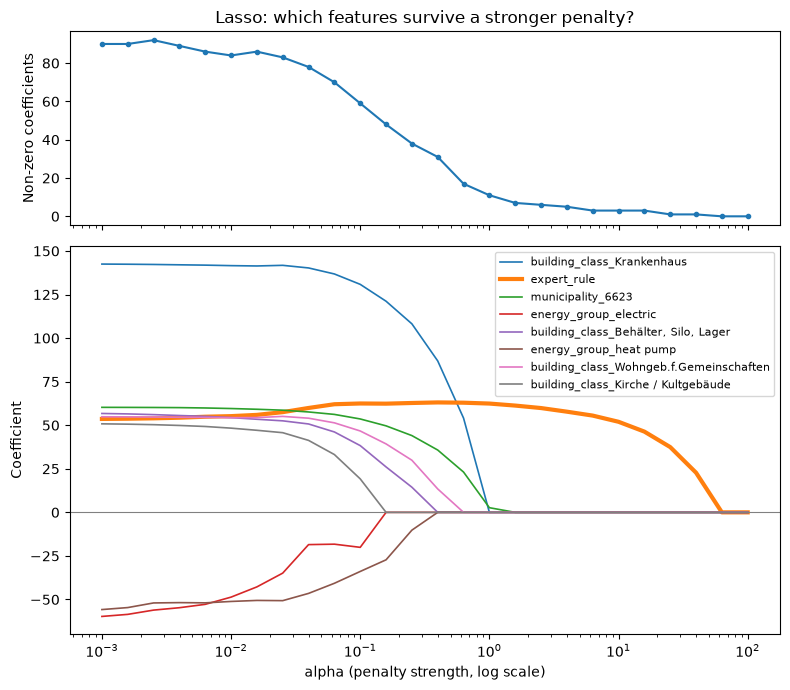

In [11]:
fig, lasso_coefs = plot_lasso_path(X, y, LASSO_ALPHAS, n_show=8, expert_rule=True,
                                   path=FIGURES / "models_lasso_path.png")
plt.show()

## 6. Task 21: classification variant (logistic regression)

The office needs to make a decision yes or no: Is this house above 450 heating index? (so that we should contact
the owner) Thus instead of predicting the index as a number through ridge and lasso, we predict the probability
of being above 450, rank houses by it, and put the top 20% on the contact list of the energy office. We judge the
model by how many houses on that list are actually above 450.

Thus an analysis check is determined: does classification predicting "yes/no" rank houses better than a number?

### 6a. Check the label, to ensure classes are balanced enough
Classification learns from "above 450: yes/no", as a value above 450 counts as a problem case. Also check that both
classes are common enough. This share is also the random reference.

In [12]:
y_class = y > THRESHOLD                                    # True = above 450
print("Houses above 450:", round(y_class[is_house].mean() * 100, 1), "%")   # about 38%
print("All buildings above 450:", round(y_class.mean() * 100, 1), "%")      # about 29%

Houses above 450: 38.0 %
All buildings above 450: 29.0 %


About 38% of houses are above 450, which is balanced enough, so no class weights are needed.

### 6b. Choosing C

Logistic regression is trained 5 times, predicts the left-out buildings, and we measure how many houses above 450
end up in the top 20%. Then we pick the setting that does best, with and without the expert rule.

In [13]:
tuning_c = pd.concat([
    results[name]["tuning"].query("group == 'houses'").assign(expert_rule=results[name]["switches"].get("expert_rule", True))
    for name in names(task=21)
])
tuning_c = pd.DataFrame({
    "expert_rule": tuning_c["expert_rule"],
    "C": tuning_c["C"],
    "top 20%: above 450 (%)": (tuning_c["share_above_top20_mean"] * 100).round(1),
    "± SE": (tuning_c["share_above_top20_se"] * 100).round(1),
}).reset_index(drop=True)
display(tuning_c)

# the better of the two logistic variants is judged below
best_logistic = max(names(task=21), key=lambda n: results[n]["summary"].query("group == 'houses'")["share_above_top20_mean"].iloc[0])
print("Best:", best_logistic, "| C =", results[best_logistic]["value"])

,expert_rule,C,top 20%: above 450 (%),± SE
0,True,0.001,53.2,4.1
1,True,0.010,51.9,3.6
2,True,0.100,52.8,2.5
3,True,1.000,53.2,2.7
4,True,10.000,53.6,2.9
5,True,100.000,53.6,2.9
6,False,0.001,49.8,1.6
7,False,0.010,53.2,3.4
8,False,0.100,51.5,2.6
9,False,1.000,53.6,2.0


Best: Logistic regression, no expert rule | C = 10.0


### 6c. Judge the chosen model

Now we check how good it really is, from three sides:

- **Main job:** How many problem houses at the top 20% of the list?
- **Mistakes:** as a yes/no rule, which mistakes does it make?
- **Competition:** is it better than the six regression models, including linear regression, ridge and lasso, each with and without the expert rule?

Every house is judged by a model that did not see it (out of fold). The test set is not used.

**Main job: are the problem houses at the top of the list?**

Step by step:
1. Our model gives every house a number between 0 and 1: the **chance of being above 450**.
2. We sort the houses from highest to lowest chance.
3. We take the **top 20%**: the houses the office would contact first.
4. We count how many of them are **really** above 450.

`evaluate` (our team's function, also used for ridge and lasso) does steps 2–4.
`predicts_index=False` leaves out the MAE, because a chance has no error in MJ/m².

In [14]:
p_best = results[best_logistic]["oof"]                # chance of being above 450, for every building (out of fold)
evaluate(y, p_best, is_house, predicts_index=False)   # top 20% above 450, for houses and all buildings

,group,n,share_above_top10,captured_top10,share_above_top20,captured_top20,mae
0,houses,1171,0.495726,0.130337,0.555556,0.292135,NaN
1,all buildings,12710,0.618411,0.213529,0.563336,0.389025,NaN


**Result.** Of the houses our model puts in the top 20%, **54.5 in 100** are really above 450 (mean over the
5 folds). If the office picked houses blindly, only **38 in 100** would be.
So the model finds about 16 more problem houses per 100 visits.

*Note:* `evaluate` above ranks all 1,171 houses together (55.6%). Everywhere else we take the top 20%
**within each fold** and average the 5 folds (**54.5%**), the same method as for ridge and lasso.
We use 54.5% for all comparisons.

**Mistakes: our model as a yes/no rule (deck 12)**

Now the model must give a clear answer for every house:
- chance **above 0.5** → "yes, problem house"
- chance **0.5 or below** → "no, fine"

We compare each answer with the truth. There are only four possibilities:

| | Model says "no" | Model says "yes" |
|---|---|---|
| **House is really fine** | correct | false alarm (wasted visit) |
| **House is really a problem** | missed | correct |

The confusion matrix shows the share of houses in each box. The measures below summarise it.

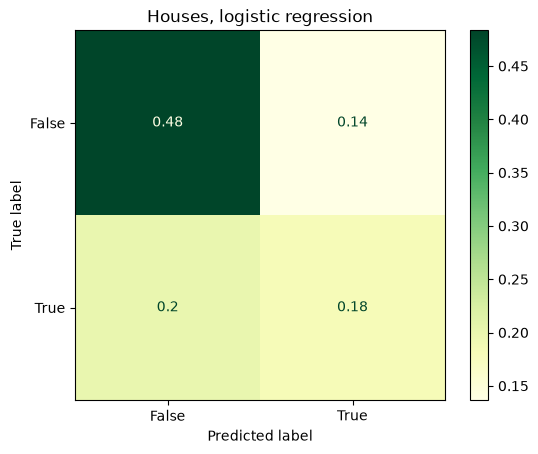

Accuracy : 0.664 | baseline: 0.62
Precision: 0.57
Recall   : 0.476
F1       : 0.519
AUC      : 0.687


In [15]:
y_hat = (p_best > 0.5).astype(int)          # yes/no with threshold t = 0.5
t, h = y_class[is_house], y_hat[is_house]   # truth and prediction, houses only

ConfusionMatrixDisplay.from_predictions(t, h, normalize="all", cmap=plt.cm.YlGn)
plt.title("Houses, logistic regression")
plt.show()

print("Accuracy :", round(accuracy_score(t, h), 3), "| baseline:", round(1 - t.mean(), 3))
print("Precision:", round(precision_score(t, h), 3))
print("Recall   :", round(recall_score(t, h), 3))
print("F1       :", round(f1_score(t, h), 3))
print("AUC      :", round(roc_auc_score(t, p_best[is_house]), 3))

**Result: the four boxes**
- **48%** of houses are fine, and the model says "no".
- **18%** are problem houses, and the model says "yes".
- **14%** are fine, but the model says "yes": the office would visit them for nothing.
- **20%** are problem houses, but the model says "no": they stay hidden.

**The measures**
- **Accuracy 0.66:** right in 66% of houses (48% + 18%). Saying "no" to everyone is already right 62% of the time,
  so the model is only a bit better on this measure (deck 12: compare accuracy with the baseline).
- **Precision 0.57:** when the model says "yes", it is right 57% of the time.
- **Recall 0.48:** of all real problem houses, the model finds about half.
- **F1 0.52:** precision and recall combined in one number.
- **AUC 0.69:** a random problem house gets a higher chance than a random fine house in 69% of cases
  (0.5 = guessing, 1 = perfect). Like our selection measure, AUC judges the **sorting**.

**What it means.** At threshold 0.5 the model misses more problem houses (20%) than it raises false alarms (14%):
it is a bit too cautious. This matters little for the office, because the office works down the sorted list
from the top instead of using a 0.5 cut.

**Competition: is our model better than the six regression models?**

Our teammates' six models (linear regression, ridge and lasso, each with and without the expert rule)
predict the heating index as a number. Step by step:
1. For each fold, count the problem houses in the top 20%, for our model and for each regression model.
2. Subtract: **our model − regression model**, on the same houses. Positive = our model is better.
3. Average the differences over the 5 folds and compute the ± SE (how much chance alone could explain).

In [16]:
def top20_mean(name):
    return results[name]["summary"].query("group == 'houses'")["share_above_top20_mean"].iloc[0] * 100

rows = []
for name in names(task=20):
    _, d = paired_difference(results[best_logistic]["per_fold"], results[name]["per_fold"])
    rows.append({
        "regression model": name,
        "regression (%)": round(top20_mean(name), 1),
        "logistic (%)": round(top20_mean(best_logistic), 1),
        "difference": d["difference (points)"],
        "± SE": d["± SE"],
        "logistic better in": d["better in"],
        "AUC regression": round(roc_auc_score(t, results[name]["oof"][is_house]), 3),
    })
classification_vs_regression = pd.DataFrame(rows)
print("AUC logistic:", round(roc_auc_score(t, p_best[is_house]), 3))
classification_vs_regression

AUC logistic: 0.687


,regression model,regression (%),logistic (%),difference,± SE,logistic better in,AUC regression
0,"Linear regression, reference",54.0,54.5,0.4,1.6,1 of 5 folds,0.684
1,"Linear regression, no expert rule",53.6,54.5,0.9,1.1,2 of 5 folds,0.686
2,"Ridge, reference",54.5,54.5,0.0,3.7,2 of 5 folds,0.669
3,"Ridge, no expert rule",53.6,54.5,0.9,1.1,2 of 5 folds,0.686
4,"Lasso, reference",54.0,54.5,0.4,1.6,1 of 5 folds,0.684
5,"Lasso, no expert rule",54.0,54.5,0.4,3.4,2 of 5 folds,0.664


**Result.** Our model is ahead by only **0.0 to 0.9 points**, less than one house per list. Chance alone could
cause differences of **1.1 to 3.7 points** (± SE), and our model wins in at most 2 of 5 folds.
The AUCs are all close (0.66–0.69).

**What it means.** Our model is **as good as** the six regression models, **but not better**.
Predicting "yes/no" sorts the houses just as well as predicting the number.

### 6d. Interpretation

**Question.** Does treating the problem as classification (above 450 or not) rank houses better than
predicting the index with regression?

**Result.**
- The best logistic regression (C = 10, without the expert rule) puts **54.5%** houses above 450 into its
  top 20%, compared with **38%** for random choice and **45.1%** for the expert rule.
- The six regression models reach **53.6–54.5%**. The differences to logistic regression are
  between **0.0 and 0.9 points**, always smaller than their standard error (1.1–3.7).
- The AUC on houses is **0.687** for logistic regression and **0.664–0.686** for the regression models.
- As a yes/no rule (threshold 0.5), logistic regression classifies **66%** of houses correctly, only a little
  above the **62%** reached by always saying "not above 450". Of the houses it flags, **57%** are real problem
  houses (precision); it finds **48%** of all problem houses (recall).
- The penalty C hardly matters: all six values give 50–54.5%, within about one standard error.

**What this means.**
- Classification ranks houses **as well as regression, but not better**. Predicting the number or predicting
  "above 450 or not" leads to almost the same list. The limit is the information in the building register,
  not the choice of model.
- At the usual threshold of 0.5, the model misses more problem houses (20% of houses) than it raises false
  alarms (14%). The office does not need this threshold, because it works down the ranking from the top.

**Decision.** We keep a regression model as the main model, because it ranks houses
equally well and also gives an estimated index and an MAE that the office can read. Logistic regression is
reported as a comparison check.

## 7. Task 22: feature sets (with and without heating information and municipality)

**Question:** how much do the heating information and the municipality add to the ranking of houses?

**Why we ask** (lecturer's feedback point 2): the register shows *today's* heating, while the target covers earlier
years. We dropped the buildings whose heating visibly changed (task 9), but for the undeclared houses, the ones the
office wants to rank, we cannot check the heating at all. So we want to know how much the model depends on it.
The municipality is the largest block of columns (one per municipality), so we also check whether it helps or only adds noise.

| Feature set | heating (energy group, heating system) | municipality | expert rule | Variant |
|---|---|---|---|---|
| Full | yes | yes | yes | reference (task 20) |
| Full, no expert rule | yes | yes | no | no expert rule (task 20) |
| No municipality | yes | no | yes | |
| No heating | no | yes | no | the expert rule needs the energy group, so it drops out too |
| No heating, no municipality | no | no | no | only size, construction period and building class |

Alpha is chosen again for every feature set (README decision 16), so no set is held back by a penalty tuned for
another one. To see what a switch removes, we count the columns after preprocessing (fitted on folds 1–4).

In [17]:
FEATURE_SETS = {   # feature set -> label of the variant
    "Full": "reference",
    "Full, no expert rule": "no expert rule",
    "No municipality": "no municipality",
    "No heating": "no heating",
    "No heating, no municipality": "no heating, no municipality",
}
switches_of = {v["label"]: v["switches"] for v in VARIANTS if v["model"] == "Ridge"}

check_train = folds != 0
n_columns = {}
for feature_set, label in FEATURE_SETS.items():
    names_out = build_preprocessor(**switches_of[label]).fit(X[check_train], y[check_train]).get_feature_names_out()
    n_columns[feature_set] = len(names_out)
pd.Series(n_columns, name="columns after preprocessing")

Full                           92
Full, no expert rule           91
No municipality                54
No heating                     72
No heating, no municipality    34
Name: columns after preprocessing, dtype: int64

In [18]:
# the selection measure on houses, one column per model
pd.DataFrame({
    model: {fs: round(top20_mean(f"{model}, {label}"), 1) for fs, label in FEATURE_SETS.items()}
    for model in ["Linear regression", "Ridge", "Lasso"]
})

,Linear regression,Ridge,Lasso
Full,54.0,54.5,54.0
"Full, no expert rule",53.6,53.6,54.0
No municipality,54.5,54.5,54.5
No heating,53.2,55.7,54.9
"No heating, no municipality",52.3,52.8,53.2


**Fold by fold: each feature set against the full set.** The means hide how much the folds differ. Here every
feature set is compared with the full set **in each fold, on the same houses and with the same model**. With about
47 houses in the top 20% of a fold, one house is about 2 points. A difference counts only if it has the same sign
in most folds and is clearly larger than its standard error.

In [19]:
rows = []
for model in ["Linear regression", "Ridge", "Lasso"]:
    for feature_set, label in list(FEATURE_SETS.items())[1:]:
        _, d = paired_difference(results[f"{model}, {label}"]["per_fold"], results[f"{model}, reference"]["per_fold"])
        rows.append({"model": model, "feature set": feature_set, **d})
pd.DataFrame(rows)

,model,feature set,difference (points),± SE,better in,worse in
0,Linear regression,"Full, no expert rule",-0.4,1.0,1 of 5 folds,1 of 5 folds
1,Linear regression,No municipality,0.4,3.4,3 of 5 folds,2 of 5 folds
2,Linear regression,No heating,-0.9,2.1,3 of 5 folds,2 of 5 folds
3,Linear regression,"No heating, no municipality",-1.7,4.4,2 of 5 folds,3 of 5 folds
4,Ridge,"Full, no expert rule",-0.9,3.3,2 of 5 folds,3 of 5 folds
5,Ridge,No municipality,0.0,1.8,1 of 5 folds,2 of 5 folds
6,Ridge,No heating,1.3,3.8,2 of 5 folds,1 of 5 folds
7,Ridge,"No heating, no municipality",-1.7,4.2,3 of 5 folds,2 of 5 folds
8,Lasso,"Full, no expert rule",0.0,2.8,3 of 5 folds,1 of 5 folds
9,Lasso,No municipality,0.4,3.4,3 of 5 folds,2 of 5 folds


**Figure.** Share of houses above 450 in the top 20% (mean over the 5 folds, bars = ± one standard error), with
random choice and the expert-rule baseline of task 18 as references.

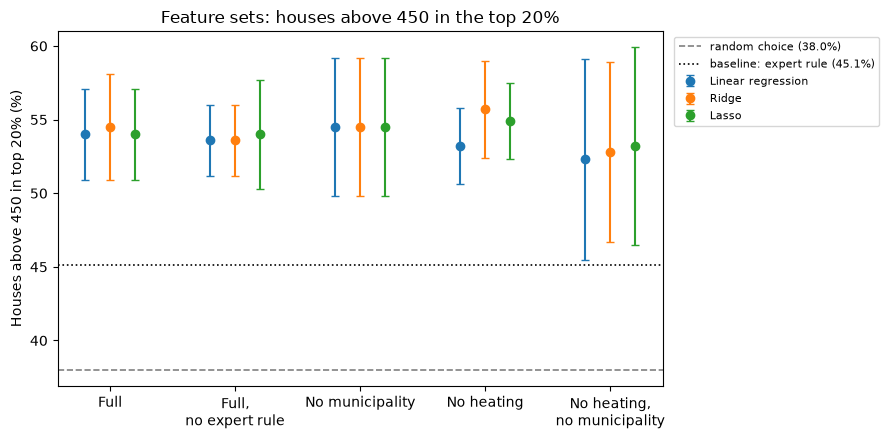

In [20]:
expert_rule_baseline = top20_mean("Expert rule, baseline")
fig, ax = plt.subplots(figsize=(9, 4.5))
labels = list(FEATURE_SETS)
models = ["Linear regression", "Ridge", "Lasso"]
for offset, model in zip(np.linspace(-0.2, 0.2, len(models)), models):
    numbers = [show(results[f"{model}, {FEATURE_SETS[fs]}"]["summary"]) for fs in labels]
    ax.errorbar(np.arange(len(labels)) + offset, [n["top 20%: above 450 (%)"] for n in numbers],
                yerr=[n["± SE"] for n in numbers], fmt="o", capsize=3, label=model)
ax.axhline(random_share * 100, color="grey", linestyle="--", linewidth=1.2, label=f"random choice ({random_share * 100:.1f}%)")
ax.axhline(expert_rule_baseline, color="black", linestyle=":", linewidth=1.2,
           label=f"baseline: expert rule ({expert_rule_baseline:.1f}%)")
ax.set_xticks(np.arange(len(labels)))
ax.set_xticklabels([label.replace(", ", ",\n") for label in labels])
ax.set_ylabel("Houses above 450 in top 20% (%)")
ax.set_title("Feature sets: houses above 450 in the top 20%")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(FIGURES / "models_feature_sets.png", dpi=150)
plt.show()

**What we found**

- **No feature set is clearly better or worse than the full set.** Over all 15 combinations the share of houses
  above 450 in the top 20% lies between 52.3% and 55.7%. Every difference to the full set (−1.7 to +1.3 points) is
  smaller than its standard error (1.0 to 4.4 points), and no feature set wins or loses in more than 3 of 5 folds.
- **Without heating information the ranking of houses is as good as with it.** Linear regression 53.2% instead of
  54.0% (−0.9 ± 2.1 points), ridge 55.7% instead of 54.5% (+1.3 ± 3.8), lasso 54.9% instead of 54.0% (+0.9 ± 1.4).
  The expert-rule column also changes nothing (−0.9 to 0.0 points, as already seen in task 20).
- **Without municipality the result is the same** (54.5% for all three models, 0.0 to +0.4 points), with 54 instead
  of 92 columns. For all buildings the measure falls a little, from 56.1–57.1% to 55.4%.
- **The smallest model (size, construction period, building class; 34 columns) is slightly lower and less stable:**
  52.3–53.2%, that is −0.9 to −1.7 points with ± 4.2 to 4.4, and its standard error over the folds doubles (6–7
  instead of about 3 points).
- **All feature sets stay well above the references:** random choice 38.0%, expert-rule baseline 45.1% (task 18).
  Even the models that do not see the heating at all rank houses better than the expert rule, which is built on
  the energy source.
- **The exact values hardly move.** MAE on houses 104.5 to 107.2 in all sets. For all buildings it rises from 75.4
  (full) to 76.6 without heating and 77.2–77.8 for the smallest model, so heating and municipality help the level a
  little, but not the order of the houses.
- **Top 10%:** the sets without heating look better here (54–57% against 43–49%), but a top 10% holds only about
  23 houses per fold, so one house is about 4 points. We do not read anything into it.

**Caution**
- For ridge and lasso, alpha was chosen on the same 5 folds we report, which makes their numbers a bit optimistic,
  for all feature sets equally. Linear regression has no alpha and is the cleanest comparison.
- We compare 5 feature sets and 3 models on about 47 houses per top 20%. With so many comparisons, a few points
  up or down are expected by chance.
- Our data only holds buildings whose heating in the register matches the target years (task 9). For undeclared
  houses the register may be out of date, so the heating information can only be less useful there than here.

**Meaning for the story** (feedback point 2): the worry that today's heating entry does not match the target years
has little weight for our result, because the ranking of houses does not depend on the heating information. Most of
what the models know about houses comes from size, construction period and building class. Which feature set goes
into the final model is decided in task 26; this notebook shows that a model without heating information would be
a defensible choice.

## 8. Task 23: trained on houses only vs. all buildings

**Question:** our models learn from *all* buildings, but only 9% of them are houses. Would a model that learns
**only from houses** rank houses better?

- **Version A, all buildings** (as in task 20): train on all buildings of the 4 training folds.
- **Version B, houses only:** train on the houses of the 4 training folds only (about 940 instead of about 10,000).

**Fair comparison:** both versions use the same 5 folds and are judged on exactly the **same validation houses**,
with the same measures (task 17). So any difference comes only from what the model learned from.

**Possible outcomes**
- B better: houses are different enough from other buildings to deserve their own model.
- A better: the extra data from other buildings helps more than it hurts.
- No clear difference: with about 47 houses in each top 20%, one house moves the measure by about 2 points.

**Ridge: alpha is chosen separately for each version.** Cross-validation uses 12,710 buildings, 1,171 of them
houses. In each fold, version A learns from 10,165 to 10,169 buildings, version B from 936 to 937 houses. With fewer
rows the model can more easily fit noise, so B might need a different penalty than A. To be fair, each version gets
its **own** best alpha, chosen with the same rule as before: the highest share of houses above 450 in the top 20%;
if two alphas are equal, the smaller MAE wins. We try the same 29 values as in task 20.

In [21]:
houses_only = pd.DataFrame([
    {"model": model, "trained on": trained_on,
     "alpha": "–" if pd.isna(results[f"{model}, {label}"]["value"]) else f"{results[f'{model}, {label}']['value']:.3g}",
     **show(results[f"{model}, {label}"]["summary"])}
    for model in ["Linear regression", "Ridge"]
    for trained_on, label in [("A: all buildings", "reference"), ("B: houses only", "houses only")]
])
houses_only

,model,trained on,alpha,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE
0,Linear regression,A: all buildings,–,54.0,3.1,49.2,28.6,104.8
1,Linear regression,B: houses only,–,57.9,2.6,58.8,30.6,108.3
2,Ridge,A: all buildings,562,54.5,3.6,43.1,28.7,106.7
3,Ridge,B: houses only,31.6,60.4,2.0,54.4,31.9,107.1


**Result:** A chooses alpha = 562.3, B chooses alpha = 31.6. The two numbers cannot be compared directly: ridge adds
up the errors over all training rows, so with more rows the same alpha has a weaker effect. Per training row, the
penalty is 562.3 / 10,168 = 0.055 for A and 31.6 / 937 = 0.034 for B. So learning from houses only does **not**
need a stronger penalty than learning from all buildings; if anything, a slightly weaker one.

**Fold by fold: in how many folds does "houses only" win?** The mean can hide a lot. Here we compare A and B
**in each fold**, on the same houses. If B wins in some folds and loses in others, the difference is most likely chance.

In [22]:
fold_tables = {}
for model in ["Linear regression", "Ridge"]:
    a, b = results[f"{model}, reference"]["per_fold"], results[f"{model}, houses only"]["per_fold"]
    diff, d = paired_difference(b, a)
    table = pd.DataFrame({
        "A: all buildings (%)": a.query("group == 'houses'").set_index("fold")["share_above_top20"] * 100,
        "B: houses only (%)": b.query("group == 'houses'").set_index("fold")["share_above_top20"] * 100,
        "B minus A (points)": diff,
    }).round(1)
    fold_tables[model] = table
    print(model)
    print(table.to_string())
    print(f"Houses only better in {d['better in']}, worse in {d['worse in']} | "
          f"mean difference {d['difference (points)']:+.1f} points (± {d['± SE']:.1f} SE)")
    print()

Linear regression
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                55.3                 8.5
1                     46.8                55.3                 8.5
2                     61.7                55.3                -6.4
3                     57.4                68.1                10.6
4                     57.4                55.3                -2.1
Houses only better in 3 of 5 folds, worse in 2 of 5 folds | mean difference +3.8 points (± 3.4 SE)

Ridge
      A: all buildings (%)  B: houses only (%)  B minus A (points)
fold                                                              
0                     46.8                57.4                10.6
1                     53.2                59.6                 6.4
2                     61.7                59.6                -2.1
3                     63.8                68.1                 4.3
4    

**What we found**

- **Houses only ranks houses better.** Share of problem houses (above 450) in the top 20%:
  linear regression 57.9% vs. 54.0%, ridge 60.4% vs. 54.5%. For the energy office: about 58–60 hits per
  100 contacted owners instead of about 54. In the top 10% the gap is even larger
  (linear regression 58.8% vs. 49.2%, ridge 54.4% vs. 43.1%).
- **The evidence is moderate.** With linear regression, houses only wins in 3 of 5 folds (+3.8 ± 3.4 points),
  which could be chance. With ridge it wins in 4 of 5 folds (+6.0 ± 2.4 points), which is more convincing.
- **The exact values get slightly worse.** MAE on houses: linear regression 108.3 vs. 104.8, ridge 107.1 vs. 106.7.
  Learning from houses only ranks them better, but is not closer in level.
- **The penalty is similar for both versions.** Ridge picks alpha = 562.3 for all buildings and 31.6 for houses only.
  Per training row (10,168 vs. 937 in fold 0) that is 0.055 vs. 0.034, so the two penalties are of the same size.
  The gain of houses only comes from learning on more relevant data, not from a different penalty.
- **Caution:** for ridge, alpha was chosen on the same 5 folds we report, which makes both ridge numbers a bit
  optimistic (for both versions equally). Linear regression has no alpha and is not affected. The final word is
  the test set (task 26).
- **Meaning for the story:** houses seem to behave differently enough from offices and apartment blocks that a model
  trained only on them ranks them better, even with 10.9 times less data (937 vs. 10,168 training rows).

## 9. All variants against their reference, and save

Every variant is compared fold by fold with the reference **of the same model** (e.g. ridge without heating vs.
ridge reference), on the same houses. Logistic regression is also compared with linear regression.
Positive difference = the variant is better.

In [23]:
rows = []
for v in VARIANTS:
    if v["model"] in BASELINES or v["label"] == "reference":
        continue
    references = [f"{v['model']}, reference"]
    if v["model"] == "Logistic regression":
        references.append("Linear regression, reference")
    for ref in references:
        _, d = paired_difference(results[v["name"]]["per_fold"], results[ref]["per_fold"])
        rows.append({"task": v["task"], "variant": v["name"], "compared with": ref, **d})
for ref in ["Logistic regression, reference"]:
    _, d = paired_difference(results[ref]["per_fold"], results["Linear regression, reference"]["per_fold"])
    rows.insert(0, {"task": 21, "variant": ref, "compared with": "Linear regression, reference", **d})
comparison = pd.DataFrame(rows)
comparison

,task,variant,compared with,difference (points),± SE,better in,worse in
0,21,"Logistic regression, reference","Linear regression, reference",-0.4,0.8,1 of 5 folds,2 of 5 folds
1,20,"Linear regression, no expert rule","Linear regression, reference",-0.4,1.0,1 of 5 folds,1 of 5 folds
2,20,"Ridge, no expert rule","Ridge, reference",-0.9,3.3,2 of 5 folds,3 of 5 folds
3,20,"Lasso, no expert rule","Lasso, reference",0.0,2.8,3 of 5 folds,1 of 5 folds
4,21,"Logistic regression, no expert rule","Logistic regression, reference",0.9,1.4,1 of 5 folds,1 of 5 folds
5,21,"Logistic regression, no expert rule","Linear regression, reference",0.4,1.6,1 of 5 folds,2 of 5 folds
6,22,"Linear regression, no municipality","Linear regression, reference",0.4,3.4,3 of 5 folds,2 of 5 folds
7,22,"Linear regression, no heating","Linear regression, reference",-0.9,2.1,3 of 5 folds,2 of 5 folds
8,22,"Linear regression, no heating, no municipality","Linear regression, reference",-1.7,4.4,2 of 5 folds,3 of 5 folds
9,22,"Ridge, no municipality","Ridge, reference",0.0,1.8,1 of 5 folds,2 of 5 folds


In [24]:
overview(names())

,setting,top 20%: above 450 (%),± SE,top 10%: above 450 (%),top 20%: captured (%),MAE,all buildings: top 20%: above 450 (%),all buildings: MAE
variant,,,,,,,,
"Training mean, baseline",–,34.0,3.9,34.5,18.0,117.5,28.8,94.8
"Expert rule, baseline",–,45.1,3.5,43.9,23.8,106.1,47.1,80.4
"Linear regression, reference",–,54.0,3.1,49.2,28.6,104.8,57.0,75.4
"Linear regression, no expert rule",–,53.6,2.4,48.3,28.3,104.5,56.4,75.5
"Ridge, reference",alpha = 562,54.5,3.6,43.1,28.7,106.7,56.1,76.5
"Ridge, no expert rule",alpha = 0.01,53.6,2.4,48.3,28.3,104.5,56.4,75.5
"Lasso, reference",alpha = 0.001,54.0,3.1,49.2,28.6,104.9,57.1,75.4
"Lasso, no expert rule",alpha = 0.631,54.0,3.7,44.0,28.5,106.8,55.1,76.9
"Logistic regression, reference",C = 10,53.6,2.9,50.1,28.3,NaN,56.2,NaN


**Saved files**
- `output/tables/models_cv_summary.csv`: every variant, mean ± SE of all measures, houses and all buildings
- `output/tables/models_cv_per_fold.csv`: the same per fold
- `output/tables/models_cv_oof.csv`: out-of-fold prediction of every variant for every building (input for the
  error analysis in `05_evaluation.ipynb`)
- `output/tables/models_cv_tuning.csv`: every value of alpha / C that was tried
- `output/tables/models_cv_comparison.csv`: the table above
- `output/tables/models_cv_classification_vs_regression.csv`: the comparison of section 6c

In [25]:
def with_info(table, r):
    info = {"variant": r["name"], "task": r["task"], "model": r["model"], "label": r["label"],
            "trained on": r["train_on"], "setting": r["param"], "value": r["value"]}
    return pd.concat([pd.DataFrame([info] * len(table)), table.reset_index(drop=True)], axis=1)

pd.concat([with_info(r["summary"], r) for r in results.values()], ignore_index=True).to_csv(TABLES / "models_cv_summary.csv", index=False)
pd.concat([with_info(r["per_fold"], r) for r in results.values()], ignore_index=True).to_csv(TABLES / "models_cv_per_fold.csv", index=False)
pd.concat([with_info(r["tuning"].rename(columns={r["param"]: "tried"}), r)
           for r in results.values() if r["tuning"] is not None], ignore_index=True).to_csv(TABLES / "models_cv_tuning.csv", index=False)

oof_table = train[["EGID", "fold", "house", "y"]].copy()
for name, r in results.items():
    oof_table[name] = r["oof"]
oof_table.to_csv(TABLES / "models_cv_oof.csv", index=False)

comparison.to_csv(TABLES / "models_cv_comparison.csv", index=False)
classification_vs_regression.to_csv(TABLES / "models_cv_classification_vs_regression.csv", index=False)
print("Saved:", len(results), "variants,", len(oof_table), "out-of-fold predictions each")

Saved: 21 variants, 12710 out-of-fold predictions each
